# Simulation
Week 3: the test recordings replayed as a stream, the way the board will see them. All numbers come from the code cells.

## Day 11 – streaming replay and alarm smoothing
Today: replay the 2021 test recordings in time order, plot the score over time (graph 4), and add accuracy rule 5: raise an alarm only when 3 of the last 5 windows are above the threshold.

### Setup
Same data, split and model as Week 2: Mahalanobis with rules 1 to 4, one model per operation. Loading reads every recording once and takes about a minute. The print checks that we get the same numbers as the `+rule4 Ledoit-Wolf` rows in `results/metrics.csv` (window AUROC 0.8896, recording AUROC 0.8934).

In [1]:
import sys
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.evaluate import ALL_RULES, METRICS, evaluate, load_data, log_row, score_test
from src.features import FS, STEP, WIN
from src.train import IDLE_COUNTS, window_rms

GOOD, BAD = '#2a78d6', '#eb6834'
idx, F = load_data()
scores = score_test('mahalanobis', idx, F, **ALL_RULES)  # score / threshold per window, idle windows dropped
before = evaluate(idx, scores)
print(f"window AUROC {before['window']['AUROC']:.4f}, recording AUROC {before['recording']['AUROC']:.4f}")

window AUROC 0.8896, recording AUROC 0.8934


### Replay order
The board gets one recording after another. The filename date is the only time information we have (the end of a 6-month period, README line 15), so periods can be put in time order, but the recordings inside one period can't. Inside a period I sort by machine, operation and file number. That order is my choice, not a fact from the data.

For each scored window I also keep its time: the end of the window in seconds from the start of its recording. Idle windows get no score, the same as on the board, so their times are skipped.

In [2]:
test = idx[idx['split'] == 'test'].sort_values(['period', 'machine', 'op', 'id'])
good, bad = test[test['label'] == 'good'].index, test[test['label'] == 'bad'].index
times = {}
for i in test.index:
    keep = window_rms(F[i]) >= IDLE_COUNTS  # the same idle rule that score_test used
    times[i] = (np.flatnonzero(keep) * STEP + WIN) / FS  # window end, s from recording start
    assert len(times[i]) == len(scores[i])
print(f"{len(test)} test recordings ({len(bad)} bad), {test['n'].sum() / FS / 3600:.2f} h of signal, "
      f"{sum(len(t) for t in times.values())} scored windows")

469 test recordings (17 bad), 6.76 h of signal, 183124 scored windows


### Alarm smoothing (rule 5)
A single window above the threshold is often just a short spike, not a fault. Rule 5 raises the alarm only when at least k of the last n windows are above the threshold. With k = 3 and n = 5 that covers 5 steps of 128 ms.

I write this as a smoothed score: the k-th largest of the last n scores. It is above 1 exactly when at least k of the n scores are above 1, so the alarm is the same, and I can still compute AUROC and PR-AUC on it. The history starts empty for every recording, because on the board a new recording means a new operation and a new model. So the first k - 1 windows of a recording can't raise an alarm. The small example checks this by hand.

In [3]:
K, N = 3, 5

def smooth(s, k=K, n=N):
    """k-th largest of the last n scores; above 1 exactly when k of the last n windows are."""
    out = np.zeros(len(s))
    for j in range(k - 1, len(s)):
        out[j] = np.sort(s[max(0, j - n + 1):j + 1])[-k]
    return out

demo = np.array([2, 0, 2, 0, 2, 0, 0, 2, 2, 2])
print('raw alarm     ', (demo > 1).astype(int))
print('smoothed alarm', (smooth(demo) > 1).astype(int))

raw alarm      [1 0 1 0 1 0 0 1 1 1]
smoothed alarm [0 0 0 0 1 0 0 0 1 1]


### Effect of rule 5
The same metrics as in Week 2, now on the smoothed scores. False alarms per hour counts the normal windows with the alarm on, the same as before. Detection delay is the time from the start of a bad recording to its first alarm (median over the bad recordings that get one). The authors cut off the start of the bad files during labelling (paper p. 135), so this is the delay from the start of the file, not from the start of the fault.

In [4]:
smoothed = {i: smooth(s) for i, s in scores.items()}
after = evaluate(idx, smoothed)

def first_alarm(s):
    """Seconds from recording start to the first alarm, for each bad recording that has one."""
    return [times[i][s[i] > 1][0] for i in bad if (s[i] > 1).any()]

def any_alarm(rows, s):
    return np.mean([(s[i] > 1).any() for i in rows])

for name, s, r in [('raw', scores, before), ('3 of 5', smoothed, after)]:
    r['recording']['delay'] = np.median(first_alarm(s))
    w, rec = r['window'], r['recording']
    print(f"{name:7} window: AUROC {w['AUROC']:.3f} PR-AUC {w['PR_AUC']:.3f} false alarms/h {w['false_alarms_per_hour']:.0f} | "
          f"recording: AUROC {rec['AUROC']:.3f} PR-AUC {rec['PR_AUC']:.3f} recall@1%FPR {rec['recall']:.3f}")
    print(f"{'':7} alarm in {any_alarm(bad, s):.0%} of bad and {any_alarm(good, s):.0%} of normal recordings, "
          f"{len(first_alarm(s))} of {len(bad)} bad detected, median delay {rec['delay']:.2f} s")

raw     window: AUROC 0.890 PR-AUC 0.306 false alarms/h 581 | recording: AUROC 0.893 PR-AUC 0.276 recall@1%FPR 0.000
        alarm in 82% of bad and 81% of normal recordings, 14 of 17 bad detected, median delay 1.66 s
3 of 5  window: AUROC 0.914 PR-AUC 0.347 false alarms/h 438 | recording: AUROC 0.878 PR-AUC 0.275 recall@1%FPR 0.000
        alarm in 71% of bad and 45% of normal recordings, 12 of 17 bad detected, median delay 1.92 s


### Log to metrics.csv
One window row and one recording row for rule 5. The check stops the rows being added a second time when the notebook runs again.

In [5]:
STEP_NAME = '+rule5 alarm 3 of 5'
if not (pd.read_csv(METRICS)['step'] == STEP_NAME).any():
    for level, m in after.items():
        log_row(STEP_NAME, 'mahalanobis', level, m, source='04_simulation.ipynb')
print(pd.read_csv(METRICS).tail(2).to_string())

          date               source                 step split      level        model  features quantization  SNR   AUROC  PR_AUC  recall_at_1pct_FPR  false_alarms_per_hour  detection_delay_s  latency_ms
14  2026-11-12  04_simulation.ipynb  +rule5 alarm 3 of 5  time     window  mahalanobis        33        float  NaN  0.9140  0.3469              0.3153                  438.0                NaN         NaN
15  2026-11-12  04_simulation.ipynb  +rule5 alarm 3 of 5  time  recording  mahalanobis        33        float  NaN  0.8778  0.2754              0.0000                    NaN               1.92         NaN


### Graph 4: score over time
One stream from the replay: machine M01, period 2021-08, with the recordings drawn back to back. Bad recordings have an orange background. Grey is the raw window score and blue is the smoothed score; the alarm is on wherever blue is above the dashed line.

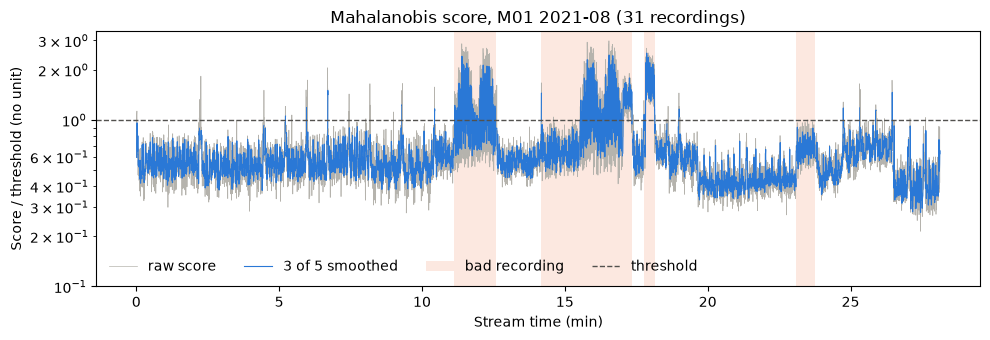

In [6]:
part = test[(test['machine'] == 'M01') & (test['period'] == '2021-08')]
fig, ax = plt.subplots(figsize=(10, 3.5))
start = 0  # s since the stream began
for n, i in enumerate(part.index):
    length = idx.loc[i, 'n'] / FS
    if idx.loc[i, 'label'] == 'bad':
        ax.axvspan(start / 60, (start + length) / 60, color=BAD, alpha=.15, lw=0, label='bad recording' if i == bad.intersection(part.index)[0] else None)
    t = (start + times[i]) / 60
    ax.plot(t, scores[i], color='#b5b3ad', lw=.5, label='raw score' if n == 0 else None)
    ax.plot(t[K - 1:], smoothed[i][K - 1:], color=GOOD, lw=.8, label='3 of 5 smoothed' if n == 0 else None)  # first K - 1 have no smoothed score
    start += length
ax.axhline(1, color='#52514e', ls='--', lw=1, label='threshold')
ax.set(yscale='log', ylim=(.1, None), title=f'Mahalanobis score, M01 2021-08 ({len(part)} recordings)',
       xlabel='Stream time (min)', ylabel='Score / threshold (no unit)')
ax.legend(frameon=False, loc='lower left', ncol=4)
fig.tight_layout()
fig.savefig('../results/figures/score_over_time.png', dpi=150)
plt.show()

### What Day 11 shows
- Rule 5 cuts false alarms from 581 to 438 per hour and raises window AUROC from 0.890 to 0.914.
- On recordings it doesn't help: AUROC drops from 0.893 to 0.878 and recall at 1% FPR stays 0. 45% of normal test recordings still get at least one alarm, so 3 of 5 is far from a usable alarm.
- 12 of 17 bad recordings raise an alarm, after a median 1.92 s from the start of the file (1.66 s without smoothing).
- In the plot, most M01 2021-08 bad recordings stand clearly above the threshold. The last one (around minute 23) stays just below it.